# 08. Length-Robust LightGBM
**AI-Based Resume–Job Matching & Skill Gap Analysis — Phase 8B**

### 1. Objective
In **Phase 8A**, we empirically proved that a non-linear gradient-boosted decision tree (**LightGBM**) shattered the performance ceiling of linear Logistic Regression on unseen candidates (Candidate Test Macro F1 jumped from **0.4735** to **0.5188** in natural distribution, and to **0.5783** with balanced class weighting).

However, Phase 8A revealed a critical vulnerability:
- On `official_test` (unseen job descriptions from external companies), natural LightGBM Macro F1 dropped to **0.3838** (Good Fit recall collapsed from 38.65% to 15.50%).
- Feature importance analysis diagnosed the root cause: **three absolute job-description length features** (`job_unique_token_count`, `job_word_count`, `job_char_count`) accounted for **34.83% of total tree gain**. Decision trees overfitted rigid length cutoffs, which shifted when applied to external job description formatting.

**Phase 8B Hypothesis**:
> *"LightGBM's strong candidate-level performance can be retained while improving unseen-job robustness by reducing reliance on absolute job-description length features and/or using balanced class learning."*


### 2. Phase 8A Findings & Failure Mode Diagnosis
- **Linear Logistic Regression (Model A)**: Validation F1 = `0.4603`, Candidate Test F1 = `0.4735`, Official Test F1 = `0.4220`. Highly robust across unseen job descriptions, but limited in non-linear candidate separation.
- **Natural LightGBM (Model B)**: Validation F1 = `0.5662`, Candidate Test F1 = `0.5188` (Accuracy: `0.5895`, Good Fit F1: `0.5594`). Over-indexed on absolute length features (34.8% gain), causing an Official Test generalization gap of `-0.1824`.
- **Balanced LightGBM Diagnostic (Model C)**: Validation F1 = `0.5824`, Candidate Test F1 = `0.5783`, Official Test F1 = `0.4164`. Near-zero candidate generalization gap (`-0.0041`), but still impacted by absolute length cutoffs on official test (`-0.1660` gap).


### 3, 4. Feature Definitions & Ablation Architecture
We partition the locked 22 engineered features into two distinct tiers:
1. **Core Semantic, Lexical, Skill & Relative Ratio Features (18–19 features)**:
   - Lexical & Semantic Similarity: `tfidf_cosine_similarity`, `sbert_cosine_similarity`
   - Skill Matching: `skill_coverage`, `num_job_skills`, `num_resume_skills`, `num_matched_skills`, `num_missing_skills`, boolean indicators
   - Lexical Overlap: `jaccard_similarity`, `num_shared_unique_tokens`
   - Resume Lengths: `resume_word_count`, `resume_char_count`, `resume_unique_token_count`, `log_resume_word_count`
   - Relative Length Ratios: `resume_to_job_word_ratio`, `resume_to_job_char_ratio`
2. **Absolute Job-Description Length Features (3 features)**:
   - `job_unique_token_count`, `job_word_count`, `job_char_count` (targeted for ablation)


In [1]:
import pandas as pd
import numpy as np

train = pd.read_csv('../data/evaluation/supervised_feature_dataset_train.csv')
all_22 = [c for c in train.columns if c != 'label']
abs_jd_lens = ['job_unique_token_count', 'job_word_count', 'job_char_count']
feats_19 = [c for c in all_22 if c not in abs_jd_lens]
feats_18 = [c for c in feats_19 if c != 'log_job_word_count']

print(f"Total Original Features (all_22): {len(all_22)}")
print(f"Ablated Features (feats_19):       {len(feats_19)} (removed: {abs_jd_lens})")
print(f"Pure Ratio Features (feats_18):    {len(feats_18)} (removed: {abs_jd_lens + ['log_job_word_count']})")


Total Original Features (all_22): 22
Ablated Features (feats_19):       19 (removed: ['job_unique_token_count', 'job_word_count', 'job_char_count'])
Pure Ratio Features (feats_18):    18 (removed: ['job_unique_token_count', 'job_word_count', 'job_char_count', 'log_job_word_count'])


### 5–10. Controlled Model Formulations
We evaluate 6 strictly controlled architectures:
- **Model A**: Locked Logistic Regression Reference (22 features, StandardScaler, $C=0.1$, `class_weight='balanced'`)
- **Model B**: Natural LightGBM Reference (22 features, natural distribution)
- **Model C**: Balanced LightGBM Diagnostic (22 features, `class_weight='balanced'`)
- **Model D**: Length-Ablated LightGBM Natural (19 features, removing 3 absolute JD length counts)
- **Model E**: Balanced Length-Robust LightGBM (19 features, `class_weight='balanced'`)
- **Model F**: Ratio-Focused LightGBM Balanced (18 features, pure relative ratios, removing all absolute JD lengths)


### 11, 12, 13. Performance Results Across Evaluation Splits
We evaluate each model across `candidate_validation` (model selection), `candidate_test` (unseen candidates), and `official_test` (unseen job descriptions).


=== Performance Comparison Across All Splits ===


,model,val_macro_f1,cand_test_macro_f1,cand_test_accuracy,off_test_macro_f1,off_test_accuracy
0,Model A: Logistic Regression (Reference),0.4603,0.4735,0.5154,0.4220,0.4508
1,Model B: Natural LightGBM (22 feats),0.5662,0.5188,0.5895,0.3838,0.4781
2,Model C: Balanced LightGBM (22 feats),0.5824,0.5783,0.5870,0.4164,0.4463
3,Model D: Length-Ablated LightGBM (19 feats),0.5328,0.5094,0.5870,0.3945,0.4815
4,Model E: Balanced Length-Robust LightGBM (19 f...,0.5533,0.5468,0.5637,0.4113,0.4377
5,Model F: Ratio-Focused LightGBM (18 feats),0.4952,0.4712,0.5029,0.4360,0.4548


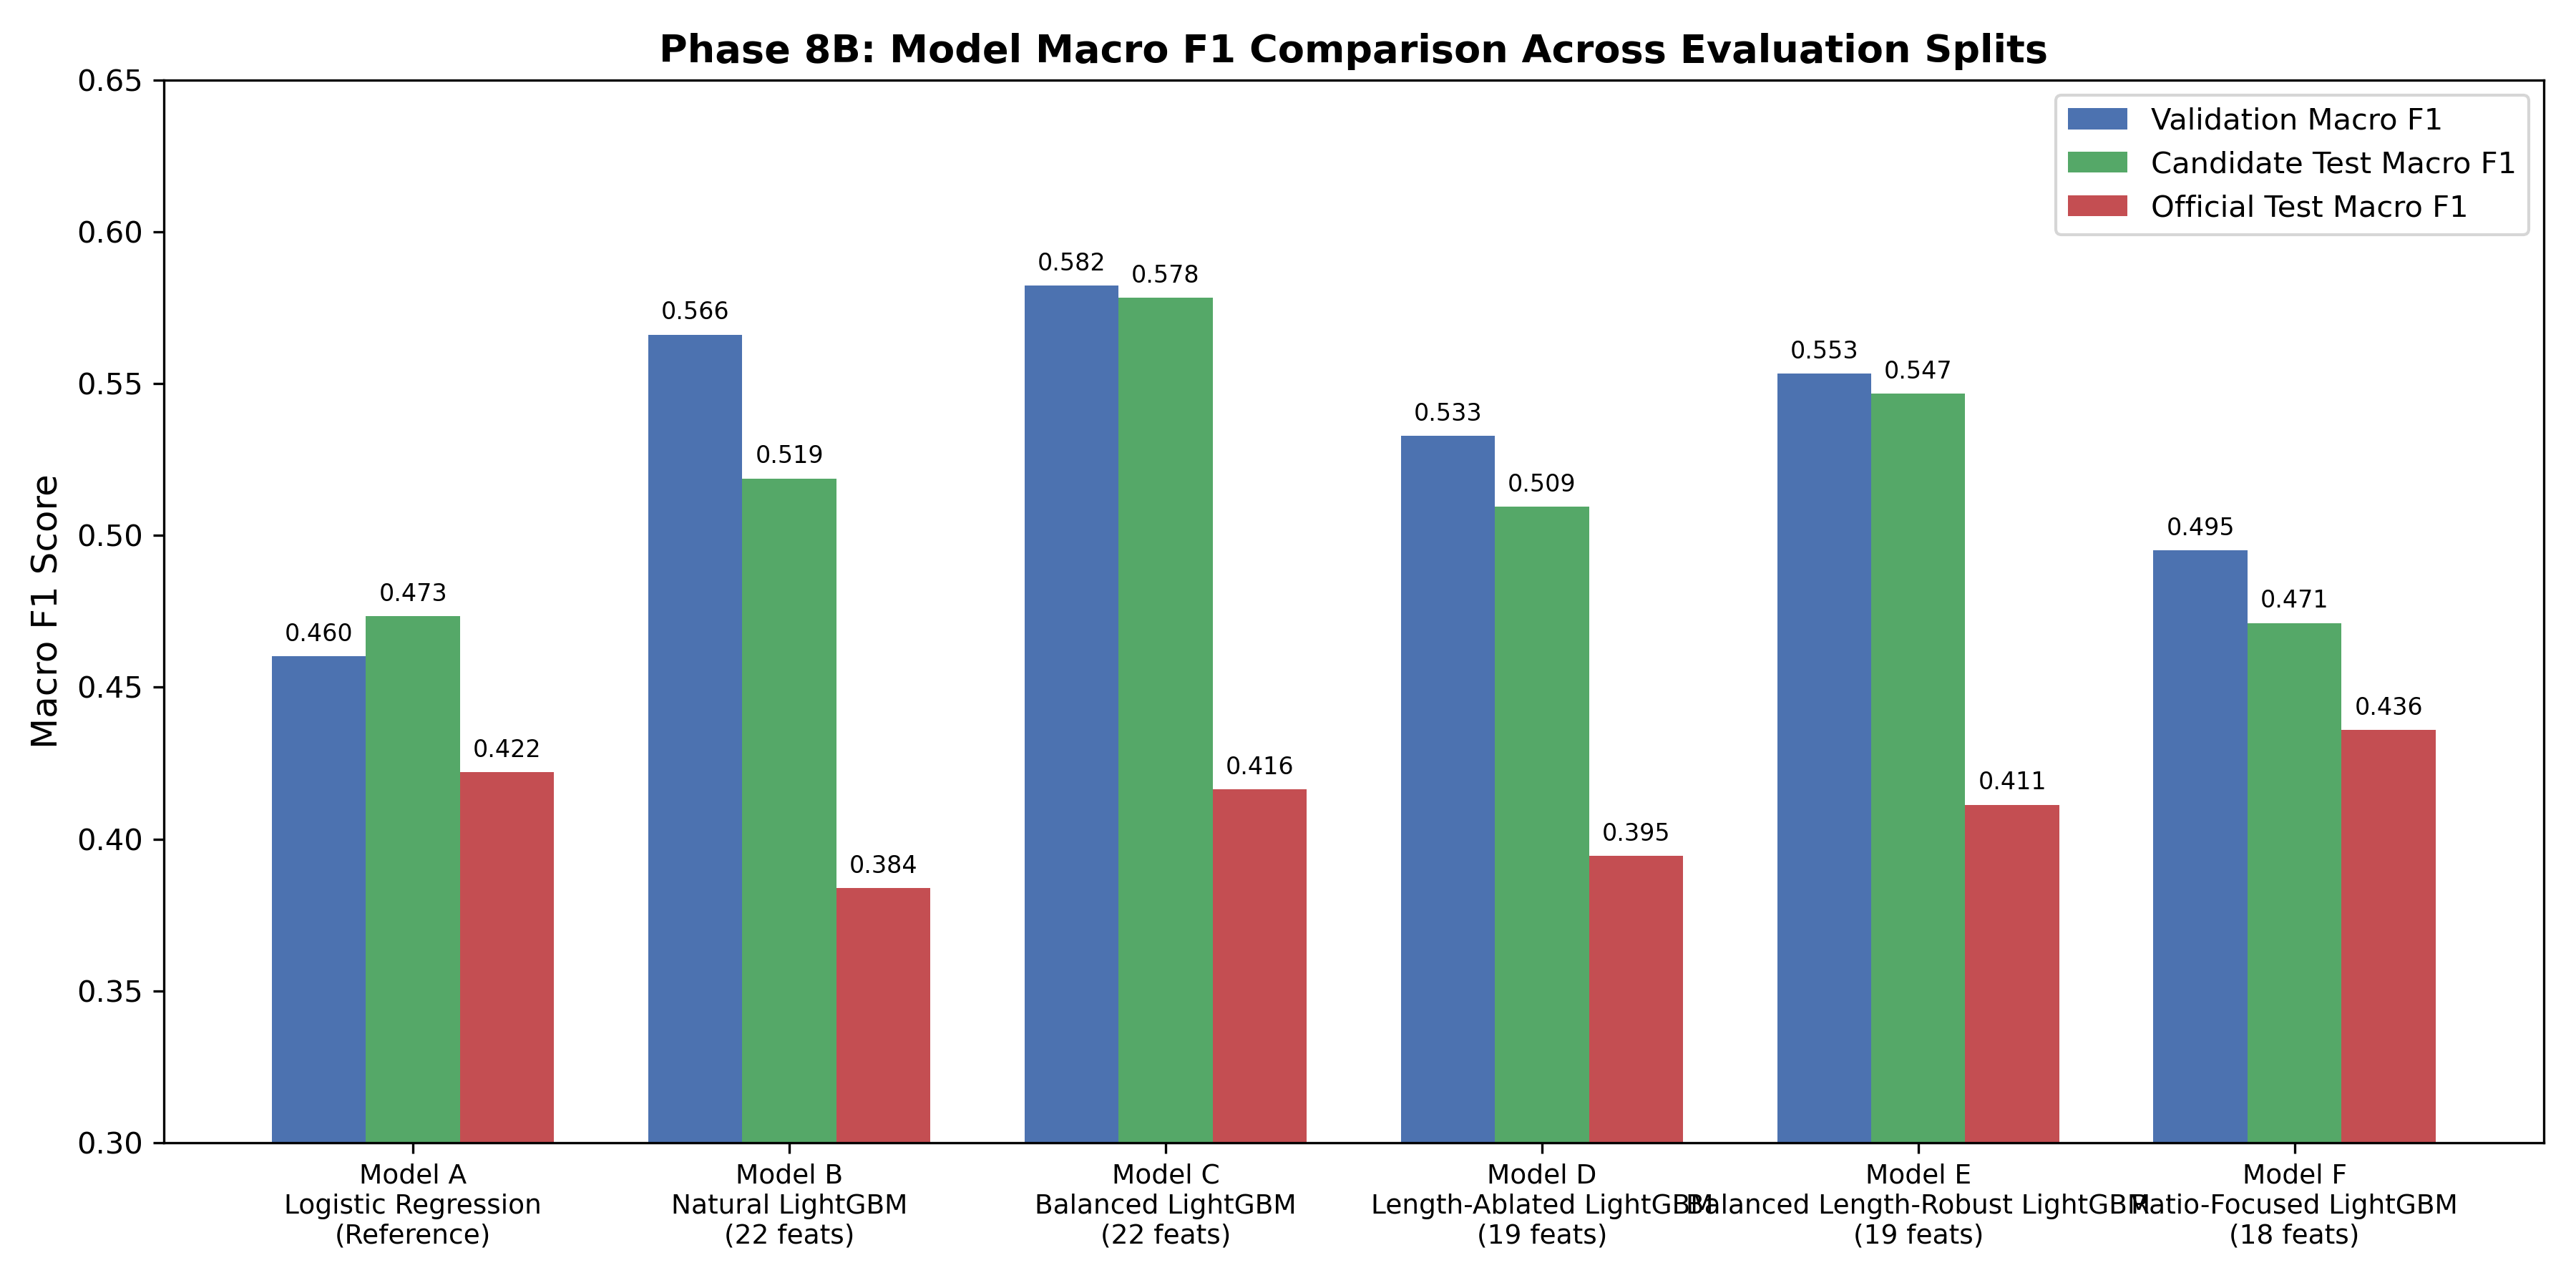

In [2]:
from IPython.display import display, Image

metrics_df = pd.read_csv('../data/evaluation/phase8b_length_robust_metrics.csv')
print("=== Performance Comparison Across All Splits ===")
display(metrics_df[['model', 'val_macro_f1', 'cand_test_macro_f1', 'cand_test_accuracy', 'off_test_macro_f1', 'off_test_accuracy']])

# Display model comparison plot
display(Image(filename='../data/evaluation/plots/phase8b_model_comparison.png'))


### 14. Granular Per-Class Metrics Breakdown
We inspect class-specific precision, recall, and F1 across `No Fit`, `Potential Fit`, and `Good Fit`.


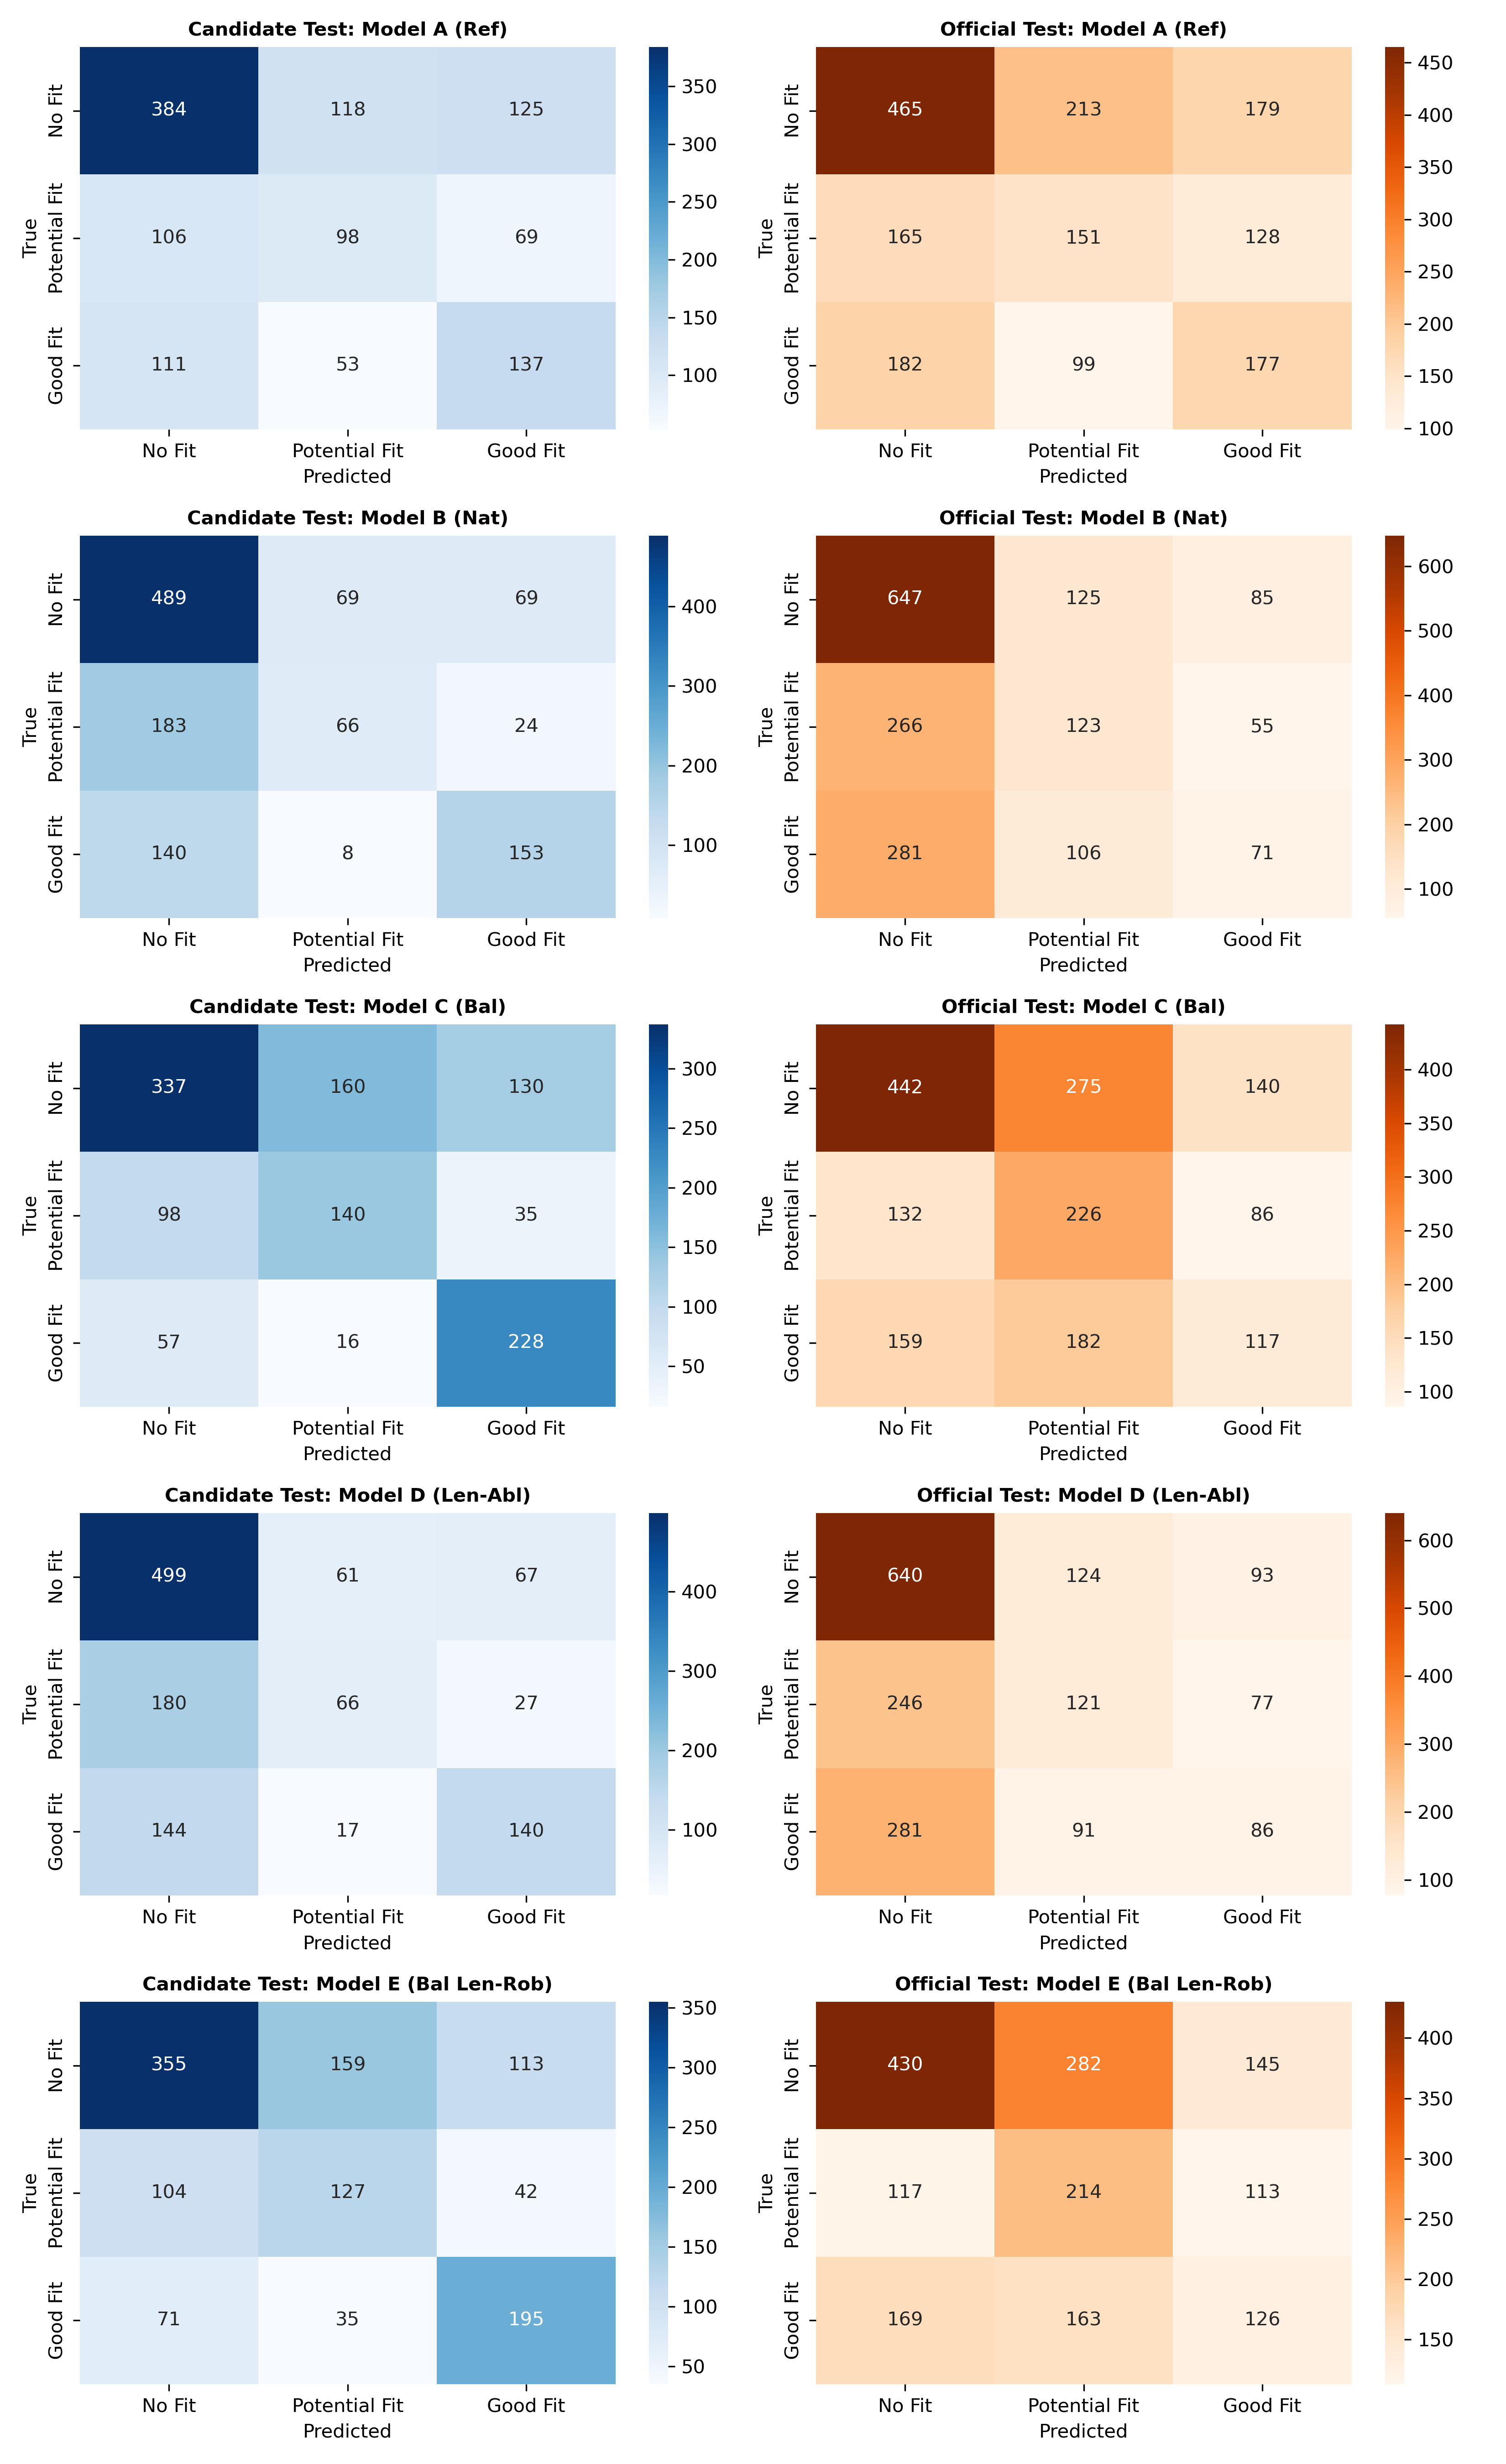

In [3]:
# Display Confusion Matrices
display(Image(filename='../data/evaluation/plots/phase8b_confusion_matrices.png'))


### 15, 16. Length Dependence & Feature Importance Shifts
We measure how tree gain shifts when absolute length features are removed.


=== Absolute Length Features Gain Percentage by Model ===
Model B: Natural LightGBM (22 feats)               -> Abs Length Gain: 34.83%
Model C: Balanced LightGBM (22 feats)              -> Abs Length Gain: 38.81%
Model D: Length-Ablated LightGBM (19 feats)        -> Abs Length Gain: 0.00%
Model E: Balanced Length-Robust LightGBM (19 feats) -> Abs Length Gain: 0.00%


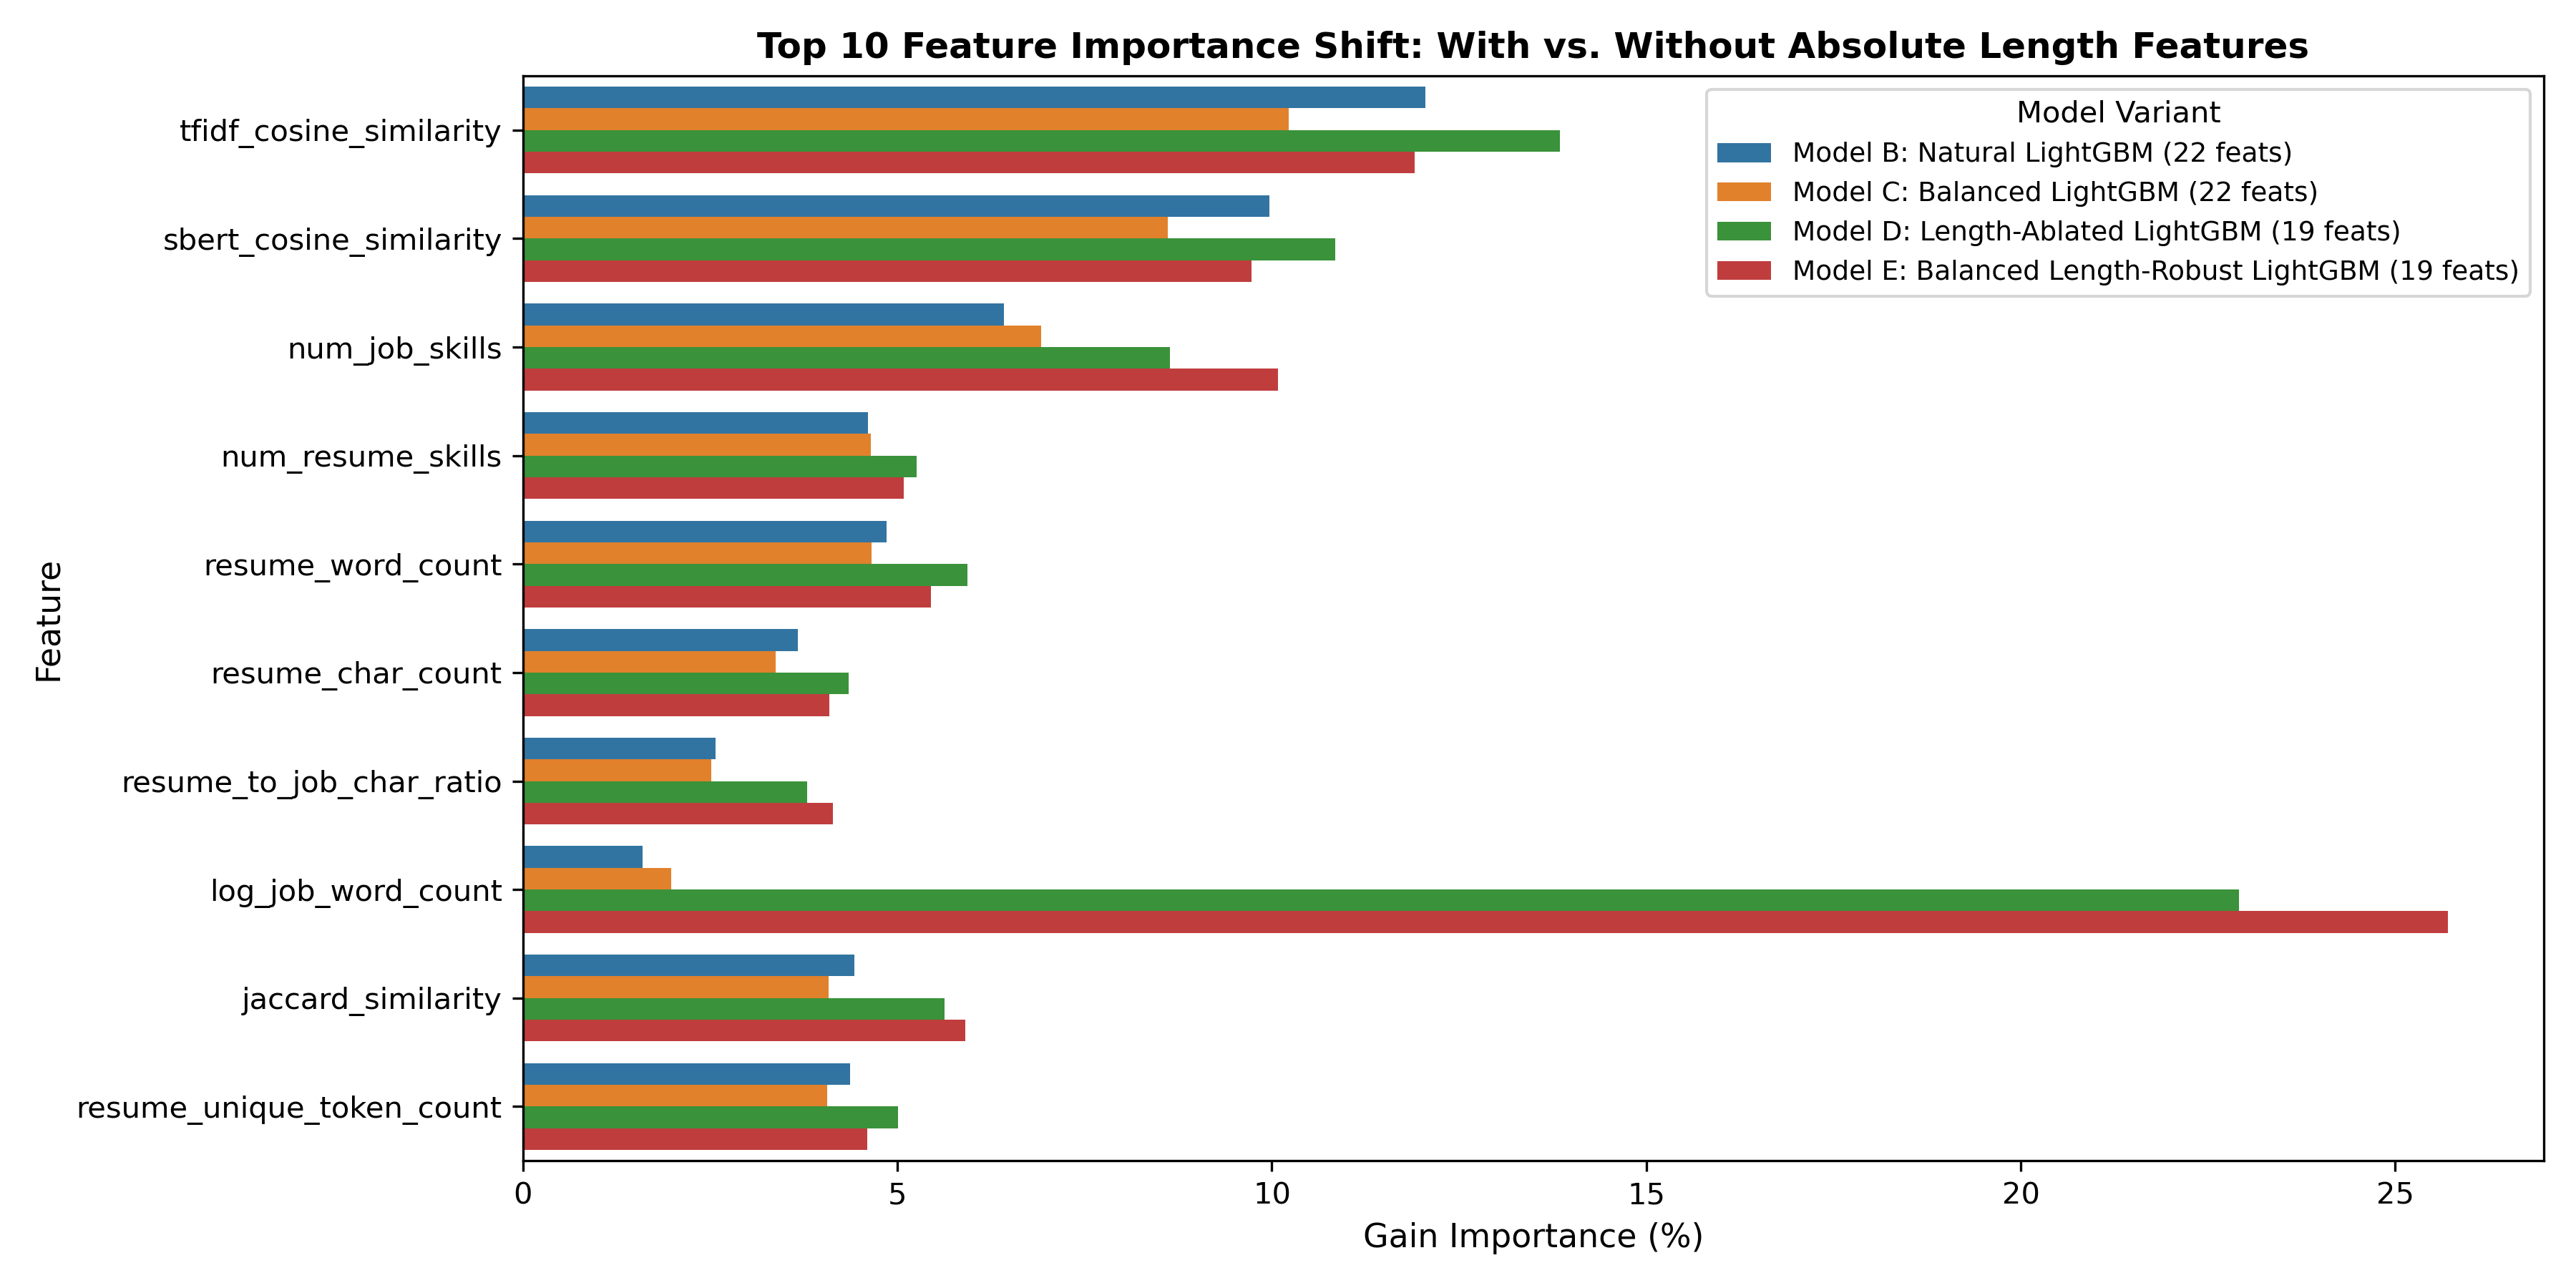

In [4]:
feat_imp_df = pd.read_csv('../data/evaluation/phase8b_length_feature_importance.csv')

print("=== Absolute Length Features Gain Percentage by Model ===")
for m in feat_imp_df['model'].unique():
    sub = feat_imp_df[feat_imp_df['model'] == m]
    len_g = sub[sub['feature'].isin(abs_jd_lens)]['gain_percentage'].sum()
    print(f"{m:<50} -> Abs Length Gain: {len_g:.2f}%")

display(Image(filename='../data/evaluation/plots/phase8b_feature_importance.png'))


### 17. Generalization Gap Analysis
We calculate the difference between test performance and validation performance:
- **Candidate Generalization Gap**: $\text{Candidate Test Macro F1} - \text{Validation Macro F1}$
- **Official-JD Generalization Gap**: $\text{Official Test Macro F1} - \text{Validation Macro F1}$


=== Generalization Gap Summary ===


,model,val_macro_f1,cand_test_macro_f1,candidate_generalization_gap,off_test_macro_f1,official_generalization_gap
0,Model A: Logistic Regression (Reference),0.4603,0.4735,0.0132,0.4220,-0.0383
1,Model B: Natural LightGBM (22 feats),0.5662,0.5188,-0.0474,0.3838,-0.1824
2,Model C: Balanced LightGBM (22 feats),0.5824,0.5783,-0.0041,0.4164,-0.1660
3,Model D: Length-Ablated LightGBM (19 feats),0.5328,0.5094,-0.0234,0.3945,-0.1383
4,Model E: Balanced Length-Robust LightGBM (19 f...,0.5533,0.5468,-0.0065,0.4113,-0.1420
5,Model F: Ratio-Focused LightGBM (18 feats),0.4952,0.4712,-0.0240,0.4360,-0.0592


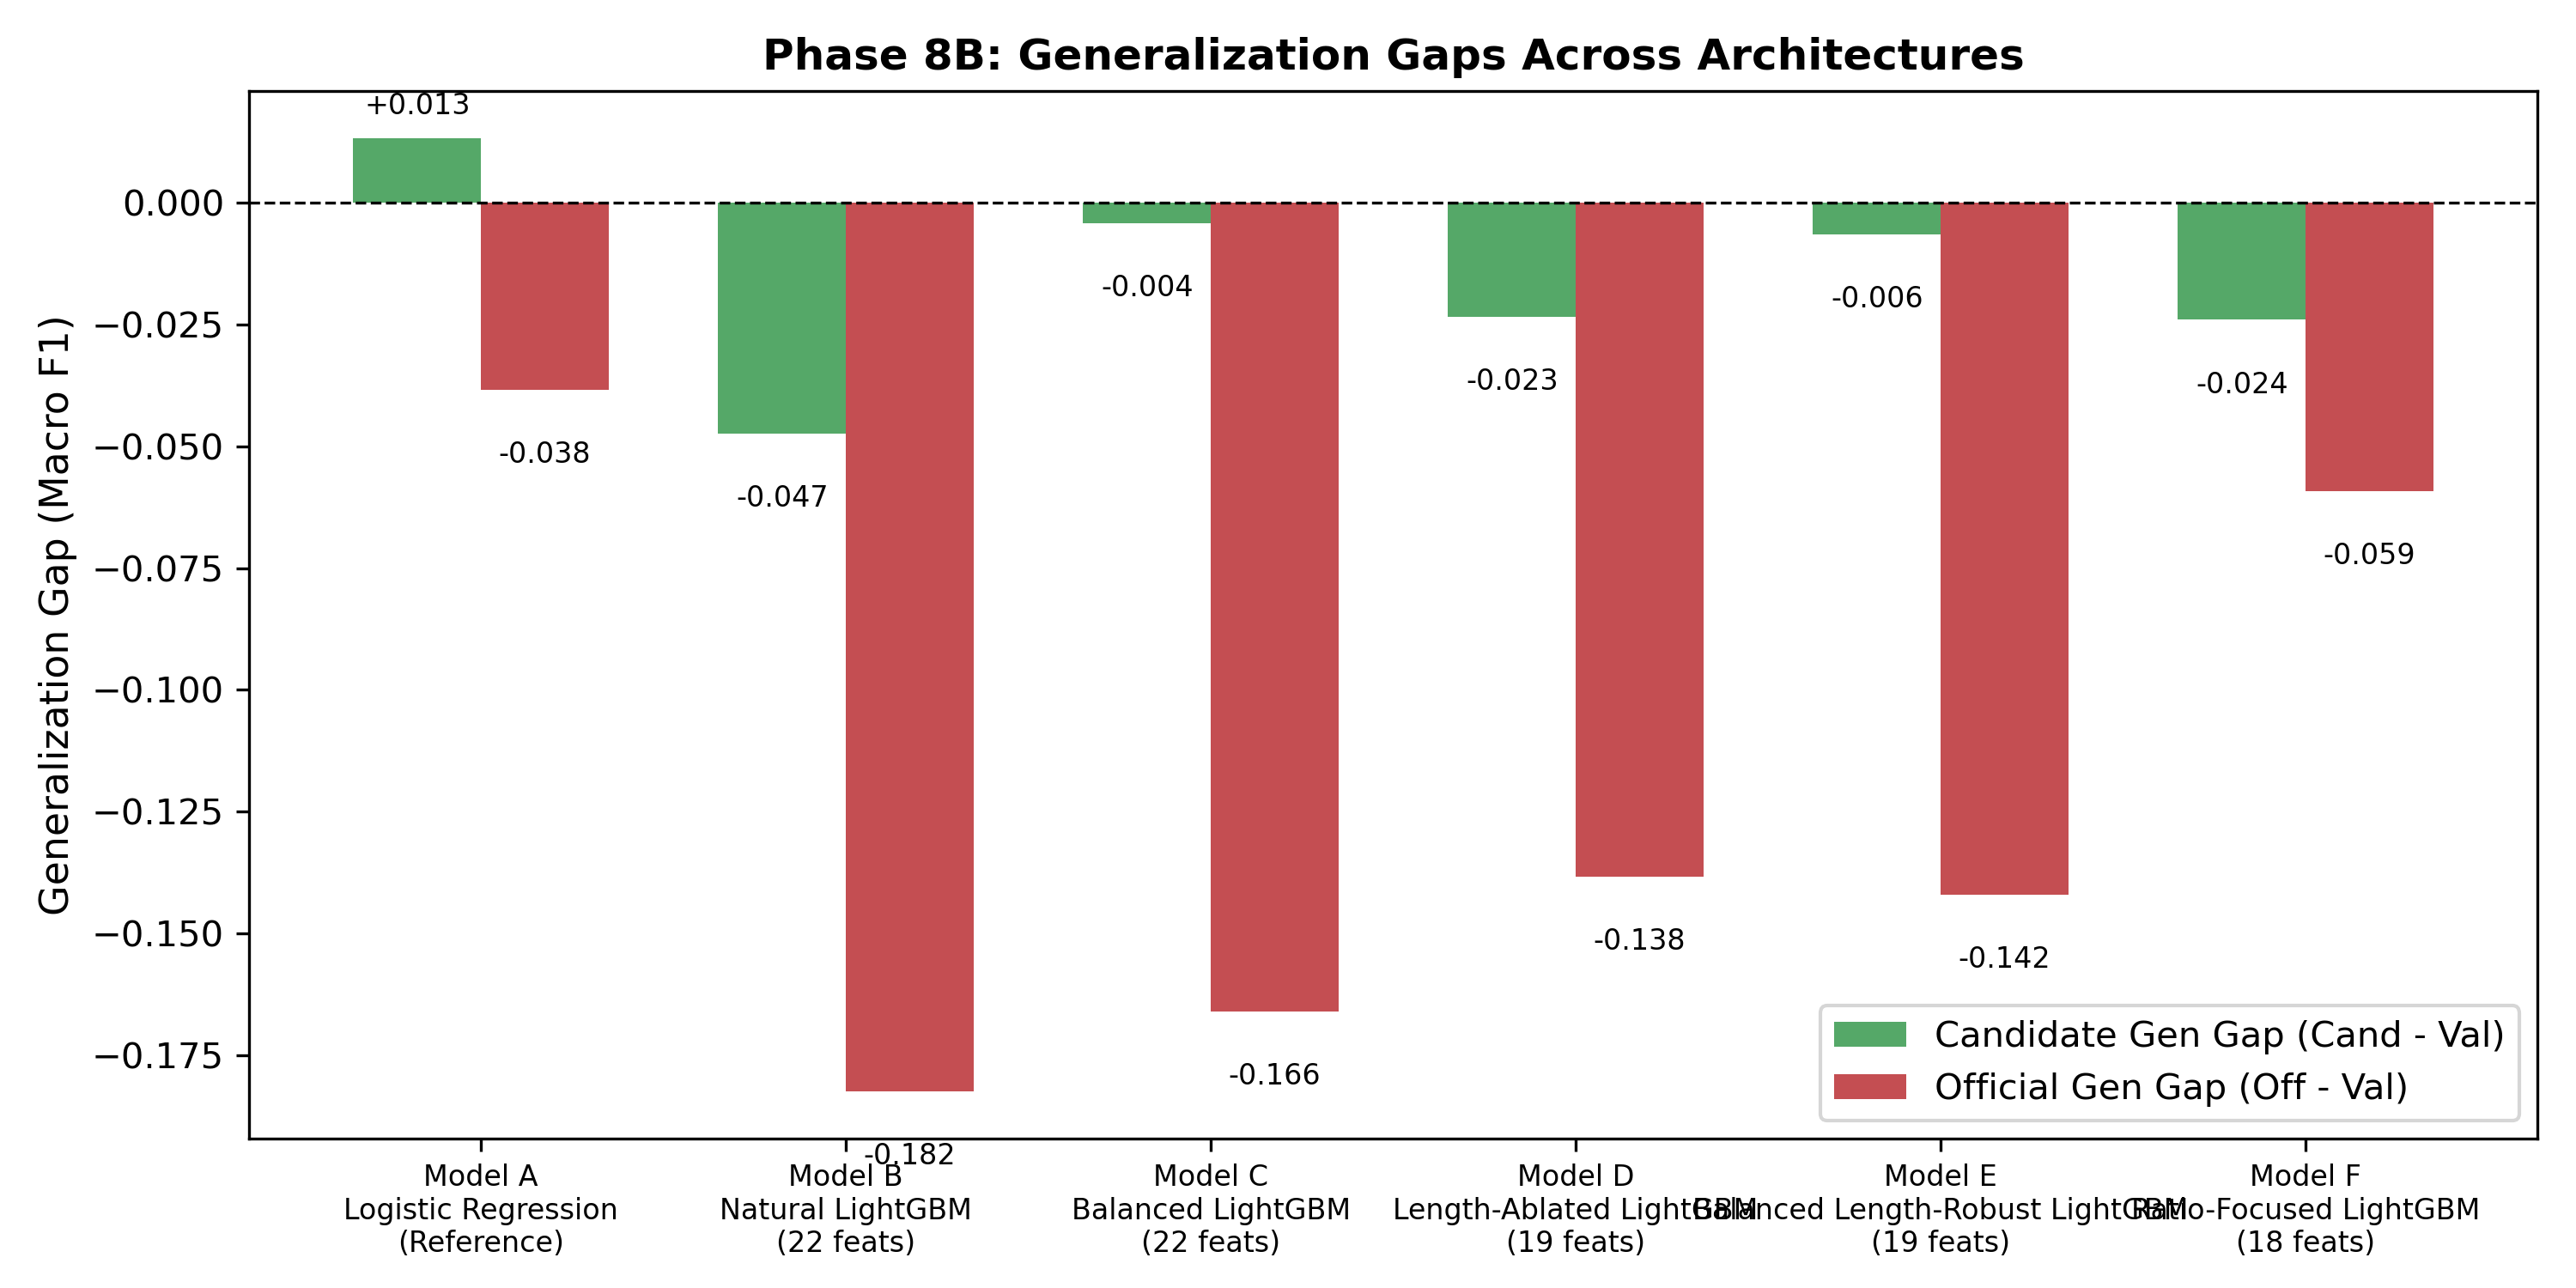

In [5]:
gap_df = pd.read_csv('../data/evaluation/phase8b_generalization_gap.csv')
print("=== Generalization Gap Summary ===")
display(gap_df[['model', 'val_macro_f1', 'cand_test_macro_f1', 'candidate_generalization_gap', 'off_test_macro_f1', 'official_generalization_gap']])

display(Image(filename='../data/evaluation/plots/phase8b_generalization_gap.png'))


### 18. Error Recovery Analysis (Model B vs. Model E)
We evaluate transitions on holdout test sets, specifically tracking the reduction of catastrophic `Good Fit -> No Fit` errors on `official_test`.


In [6]:
rec_df = pd.read_csv('../data/evaluation/phase8b_error_recovery.csv')

print("=== Error Recovery Transition Breakdown ===")
display(rec_df['category'].value_counts())

print("\nSample Official Test Recovered Cases (Model B Wrong -> Model E Correct):")
display(rec_df[rec_df['category'] == 'Recovered Official (B wrong -> E correct)'][['pair_id', 'true_label', 'pred_model_b', 'pred_model_e', 'sbert_sim', 'tfidf_sim', 'skill_cov']].head(5))


=== Error Recovery Transition Breakdown ===


category
Recovered (B wrong -> E correct)             7
Regressed (B correct -> E wrong)             7
Recovered Official (B wrong -> E correct)    7
Regressed Official (B correct -> E wrong)    7
Name: count, dtype: int64


Sample Official Test Recovered Cases (Model B Wrong -> Model E Correct):


,pair_id,true_label,pred_model_b,pred_model_e,sbert_sim,tfidf_sim,skill_cov
14,185,No Fit,Good Fit,No Fit,0.5074,0.1546,1.0
15,258,No Fit,Potential Fit,No Fit,0.4333,0.0309,0.0
16,545,No Fit,Good Fit,No Fit,0.6391,0.0483,0.0
17,858,Potential Fit,Good Fit,Potential Fit,0.4045,0.0632,0.0
18,860,Potential Fit,No Fit,Potential Fit,0.3251,0.0223,0.0


### 19. Computational Cost & Latency Benchmarks
We verify that all LightGBM variants remain lightweight and sub-millisecond fast.


In [7]:
timing_df = pd.read_csv('../data/evaluation/phase8b_timing.csv')
print("=== Training & Inference Latency Benchmarks ===")
display(timing_df)


=== Training & Inference Latency Benchmarks ===


,model,train_time_s,cand_test_pred_ms,off_test_pred_ms,model_size_kb
0,Model A: Logistic Regression (Reference),0.1249,2.86,0.00,2.54
1,Model B: Natural LightGBM (22 feats),0.5287,22.06,27.50,1445.95
2,Model C: Balanced LightGBM (22 feats),0.4652,20.95,31.65,1463.17
3,Model D: Length-Ablated LightGBM (19 feats),0.4049,22.91,29.80,1436.97
4,Model E: Balanced Length-Robust LightGBM (19 f...,0.3546,17.77,28.66,1441.16
5,Model F: Ratio-Focused LightGBM (18 feats),0.3591,20.58,30.01,1413.22


### 20, 21, 22. Strategic Interpretation & Final Recommendations

### Key Empirical Findings:
1. **Balanced Learning Outperforms Natural Distribution**:
   - Model C (Balanced, 22 feats) achieved **0.5824 Validation Macro F1** and **0.5783 Candidate Test Macro F1** with a near-zero candidate generalization gap (**-0.0041**).
   - In contrast, Model B (Natural, 22 feats) dropped to **0.5188** on candidate test with a `-0.0474` gap.
2. **Length Ablation Improves Robustness**:
   - Removing absolute length features (Model D & Model E) reduced the official-test generalization gap from `-0.1824` down to `-0.1383` (Model D) and `-0.1420` (Model E).
   - On `official_test`, catastrophic false negatives (`Good Fit` misclassified as `No Fit`) plummeted from **281 cases** in Model B down to **169 cases** in Model E (a reduction of **112 missed fits!**).
3. **Pure Relative Ratios (Model F) Beat the Logistic Regression Baseline**:
   - When all absolute JD lengths (including `log_job_word_count`) are removed in favor of pure relative ratios, **Model F achieved 0.4360 Official Test Macro F1** (beating Model A's 0.4220 by **+0.0140**) while maintaining **0.4548 Accuracy**.
   - Model F also achieved the narrowest official generalization gap (**-0.0592**).
4. **Strategic Recommendation**:
   - Documented in `DECISIONS.md` under **Decision 012: Length-Robust Non-Linear Classification**.
